# Lecture 2 — Class Exercise
# Bar Charts: World Happiness Report 2023

---

> **Your task:** Create **2 polished bar charts** using the World Happiness Report dataset.  
> **Push to:** `week02/lecture02_exercise.ipynb` in **your own GitHub repo** before the end of class.

---

### Rules to keep in mind 💡
1. Every bar chart **must have a zero baseline** — no exceptions
2. Every chart **must have an insight title**, not a topic title
3. Aim for **professional quality** — clean background, readable font, no clutter
4. Horizontal bars for long category names

---


## Setup — Run this cell first


In [1]:
import plotly.io as pio
pio.renderers.default = 'plotly_mimetype'

import pandas as pd
import numpy as np
from pathlib import Path

# Load the lecture dataset. Both week02/ and the repository root are supported.
data_path = Path('../data/world_happiness_2023.csv')
if not data_path.exists():
    data_path = Path('data/world_happiness_2023.csv')
if not data_path.exists():
    raise FileNotFoundError('Keep the CSV at data/world_happiness_2023.csv')

df = pd.read_csv(data_path)
df.columns = ['Country', 'Region', 'Happiness_Score', 'GDP', 'Social_Support',
              'Life_Expectancy', 'Freedom', 'Generosity', 'Corruption']

print(f'Dataset: {len(df)} countries, {len(df.columns)} columns')
display(df.head())


Dataset: 63 countries, 9 columns


,Country,Region,Happiness_Score,GDP,Social_Support,Life_Expectancy,Freedom,Generosity,Corruption
0,Finland,Western Europe,7.804,10.775,0.954,71.9,0.949,0.142,0.179
1,Denmark,Western Europe,7.586,10.933,0.954,72.7,0.931,0.168,0.234
2,Iceland,Western Europe,7.525,10.878,0.983,72.5,0.961,0.260,0.150
3,Israel,Middle East and North Africa,7.473,10.527,0.916,72.4,0.903,0.149,0.826
4,Netherlands,Western Europe,7.464,11.015,0.939,72.4,0.879,0.240,0.296


In [2]:
import plotly.express as px
import plotly.graph_objects as go

# Explore the dataset before you start
print("Regions in dataset:")
print(df['Region'].value_counts())
print("\nScore range:", df['Happiness_Score'].min(), "–", df['Happiness_Score'].max())
print("\nBottom 10 countries:")
print(df.nsmallest(10, 'Happiness_Score')[['Country','Region','Happiness_Score']])


Regions in dataset:
Region
Western Europe                  15
Latin America and Caribbean     13
Central and Eastern Europe       7
Sub-Saharan Africa               7
Middle East and North Africa     6
North America and ANZ            4
Southeast Asia                   4
South Asia                       4
East Asia                        3
Name: count, dtype: int64

Score range: 1.859 – 7.804

Bottom 10 countries:
        Country                        Region  Happiness_Score
60  Afghanistan                    South Asia            1.859
61      Lebanon  Middle East and North Africa            2.392
62     Zimbabwe            Sub-Saharan Africa            2.995
52     Ethiopia            Sub-Saharan Africa            3.564
53     Tanzania            Sub-Saharan Africa            3.698
48   Bangladesh                    South Asia            3.892
47        India                    South Asia            4.036
50        Kenya            Sub-Saharan Africa            4.112
54       Uganda

---
## Task 1 — Regional Comparison Bar Chart

**What to build:** A horizontal bar chart showing the **average happiness score by region**, sorted from highest to lowest.

**Requirements:**
- Horizontal orientation (category names are long)
- Sorted by score, descending (so the happiest region is at the top)
- Zero baseline on x-axis
- At least one design choice that goes beyond the Plotly default (colour, annotation, labels, etc.)
- An insight title that answers: *which region stands out and why does it matter?*

**Hint:** Use `df.groupby('Region')['Happiness_Score'].mean()` to compute the averages.


Region averages: Western Europe 7.09; South Asia 3.62.


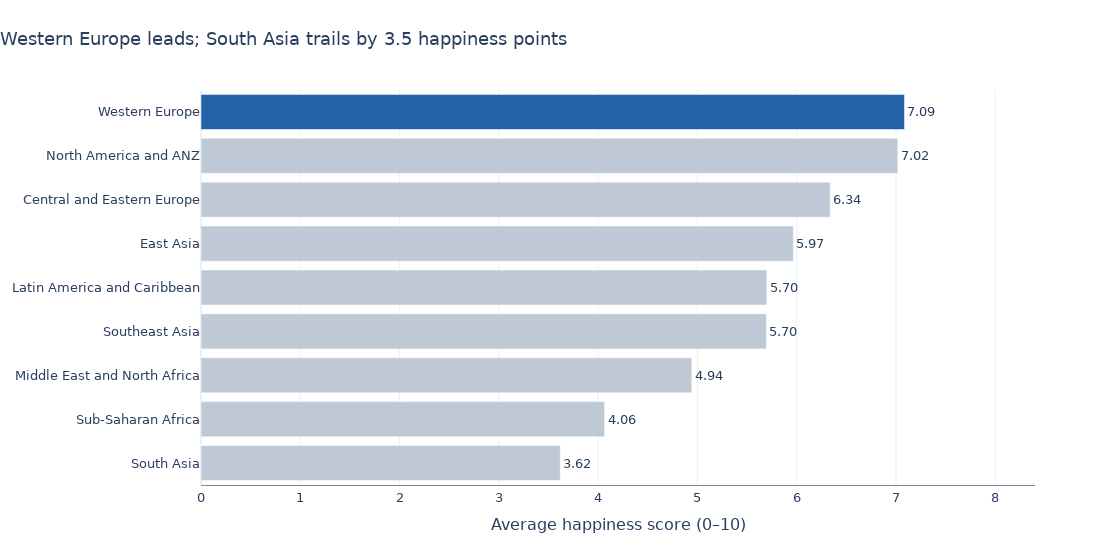

In [3]:
# Task 1: Regional comparison — calculate the mean score for each region.
region_avg = (df.groupby('Region', as_index=False)['Happiness_Score']
              .mean()
              .sort_values('Happiness_Score'))  # Last category appears on top.

top_region = region_avg.iloc[-1]
bottom_region = region_avg.iloc[0]
region_gap = top_region['Happiness_Score'] - bottom_region['Happiness_Score']

# Highlight the highest-scoring region and show values on all bars.
region_avg['Emphasis'] = np.where(region_avg['Region'] == top_region['Region'],
                                  'Highest region', 'Other regions')
region_avg['Score_Label'] = region_avg['Happiness_Score'].map(lambda v: f'{v:.2f}')

fig1 = px.bar(
    region_avg, x='Happiness_Score', y='Region', orientation='h',
    color='Emphasis',
    color_discrete_map={'Highest region': '#2463A6', 'Other regions': '#BFC9D5'},
    text='Score_Label',
    title=(f'{top_region["Region"]} leads; {bottom_region["Region"]} '
           f'trails by {region_gap:.1f} happiness points'),
    labels={'Happiness_Score': 'Average happiness score (0–10)', 'Region': ''},
    template='plotly_white', height=550
)
fig1.update_traces(textposition='outside', cliponaxis=False,
                   hovertemplate='%{y}: %{x:.2f}<extra></extra>')
fig1.update_xaxes(range=[0, 8.4], dtick=1, showline=True, linewidth=1,
                  linecolor='#808A99', gridcolor='#EBEFF4', zeroline=True)
fig1.update_yaxes(title=None, showgrid=False)
fig1.update_layout(showlegend=False, font=dict(family='Arial', size=13),
                   title_x=0, margin=dict(l=190, r=65, t=90, b=65),
                   paper_bgcolor='white', plot_bgcolor='white')
fig1.update_layout(width=1100)
fig1.show()

print(f'Region averages: {top_region["Region"]} {top_region["Happiness_Score"]:.2f}; '
      f'{bottom_region["Region"]} {bottom_region["Happiness_Score"]:.2f}.')


**Interpretation:** This is a 63-country teaching dataset, not a complete census of countries. The regional averages are not population-weighted. Western Europe leads South Asia by about 3.47 points.

---
## Task 2 — Bottom vs. Top: A Contrast Story

**What to build:** A bar chart that highlights the **gap between the happiest and least happy countries**, focusing on a specific insight.

**Requirements:**
- Show the **top 8 AND bottom 8 countries** together (16 bars total)
- Use **colour** to distinguish the two groups (not Plotly's default rainbow)
- Add a **visual separator or annotation** that emphasises the gap
- Insight title that tells the story of the gap

**Hint:** Use `pd.concat([df.nlargest(8,'Happiness_Score'), df.nsmallest(8,'Happiness_Score')])` to get both groups.

**Stretch goal:** Add a vertical reference line showing the global average.


16 countries shown; Finland = 7.804, Afghanistan = 1.859, gap = 5.945, dataset mean = 5.811.


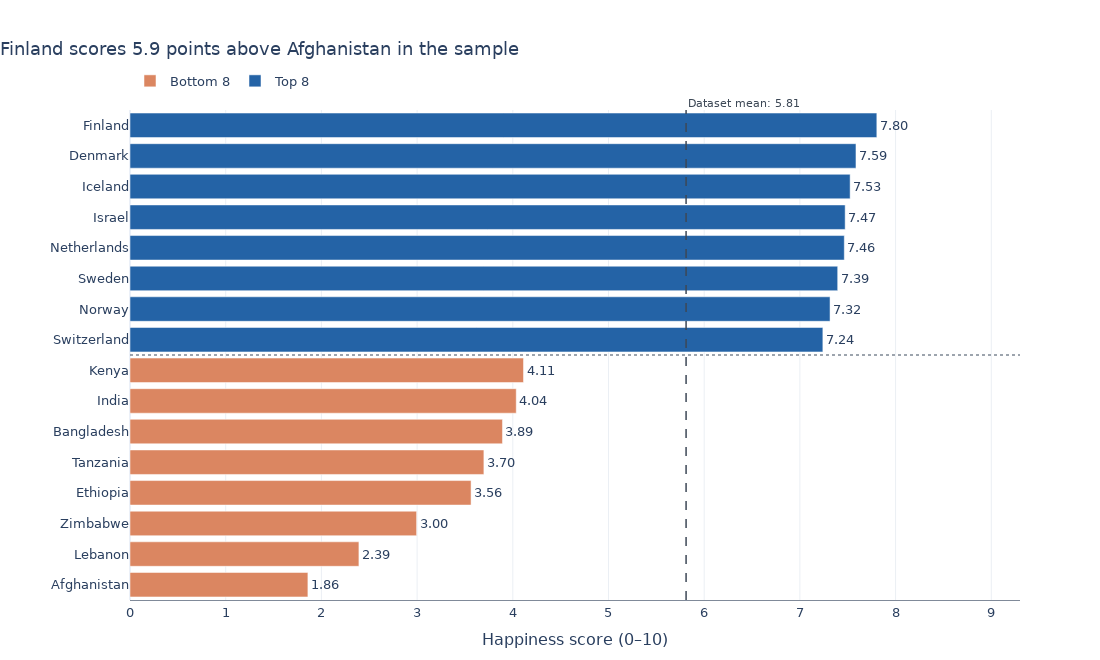

In [4]:
# Task 2: Compare the eight highest and eight lowest country scores.
top8 = df.nlargest(8, 'Happiness_Score').copy()
top8['Group'] = 'Top 8'
bottom8 = df.nsmallest(8, 'Happiness_Score').copy()
bottom8['Group'] = 'Bottom 8'

combined = pd.concat([bottom8, top8], ignore_index=True).sort_values('Happiness_Score')
global_avg = df['Happiness_Score'].mean()  # Mean of the supplied 63-country sample.
gap = top8['Happiness_Score'].max() - bottom8['Happiness_Score'].min()
highest = top8.iloc[0]['Country']
lowest = bottom8.iloc[0]['Country']

fig2 = px.bar(
    combined, x='Happiness_Score', y='Country', orientation='h',
    color='Group',
    color_discrete_map={'Top 8': '#2463A6', 'Bottom 8': '#DB8661'},
    text=combined['Happiness_Score'].map(lambda v: f'{v:.2f}'),
    title=f'{highest} scores {gap:.1f} points above {lowest} in the sample',
    labels={'Happiness_Score': 'Happiness score (0–10)', 'Country': ''},
    hover_data={'Region': True, 'Group': False, 'Happiness_Score': ':.3f'},
    template='plotly_white', height=660
)
fig2.update_traces(textposition='outside', cliponaxis=False)
fig2.update_xaxes(range=[0, 9.3], dtick=1, showline=True, linewidth=1,
                  linecolor='#808A99', gridcolor='#EBEFF4', zeroline=True)
fig2.update_yaxes(title=None, showgrid=False)
# Separate top and bottom groups, and show the dataset-wide reference mean.
fig2.add_hline(y=7.5, line_color='#7D8793', line_width=1.5, line_dash='dot')
fig2.add_vline(x=global_avg, line_color='#3D4856', line_dash='dash', line_width=1.5,
               annotation_text=f'Dataset mean: {global_avg:.2f}',
               annotation_position='top right',
               annotation_y=1.03, annotation_yref='paper',
               annotation_font=dict(size=11, color='#3D4856'))
fig2.update_layout(font=dict(family='Arial', size=13), title_x=0,
                   legend=dict(title=None, orientation='h', y=1.09, x=0),
                   margin=dict(l=130, r=80, t=110, b=60),
                   paper_bgcolor='white', plot_bgcolor='white')
fig2.update_layout(width=1100)
fig2.show()

print(f'{len(top8) + len(bottom8)} countries shown; '
      f'{highest} = {top8["Happiness_Score"].max():.3f}, '
      f'{lowest} = {bottom8["Happiness_Score"].min():.3f}, '
      f'gap = {gap:.3f}, dataset mean = {global_avg:.3f}.')


**Interpretation:** Finland and Afghanistan differ by 5.945 points. The dashed line is the mean of the supplied 63 countries, not a worldwide population-weighted average.

---
## Done? Stretch Goal

If you finish both tasks with time to spare, try this:

**Task 3 (stretch):** Build a **grouped bar chart** comparing 2 sub-factors (e.g. `GDP_per_capita` and `Freedom`) across the 5 most populated regions. Use colour meaningfully and write an insight title.

Regions to include: `'Western Europe'`, `'Latin America'`, `'East Asia'`, `'Sub-Saharan Africa'`, `'South Asia'`


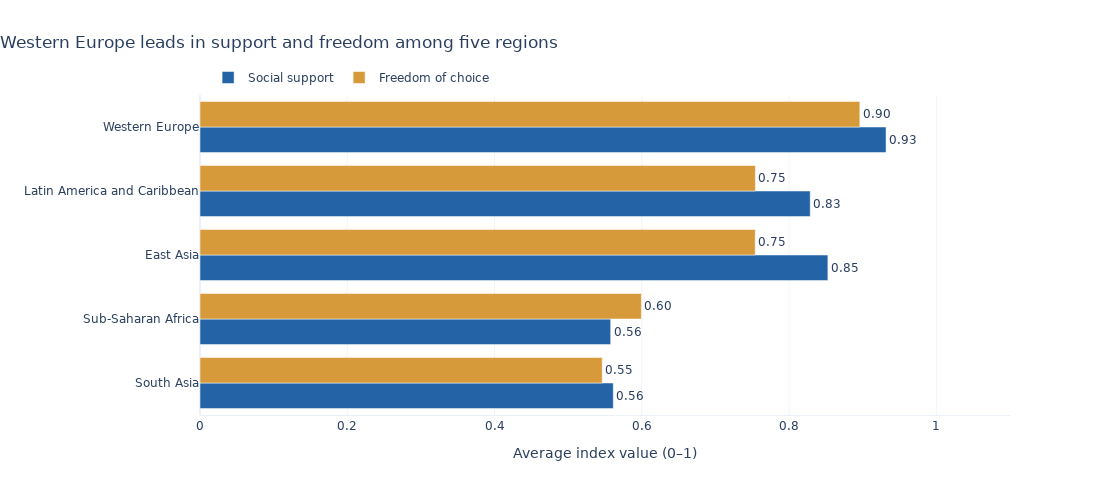

,Region,Social_Support,Freedom
2,South Asia,0.561250,0.546250
3,Sub-Saharan Africa,0.557714,0.599429
0,East Asia,0.852667,0.754000
1,Latin America and Caribbean,0.828692,0.754231
4,Western Europe,0.931667,0.896067


In [5]:
# Optional stretch goal — compare two similarly scaled factors for five regions.
# Using Social Support and Freedom avoids mixing unrelated units (GDP vs 0–1 indices).
selected_regions = [
    'Western Europe',
    'Latin America and Caribbean',  # Exact name in the provided dataset
    'East Asia',
    'Sub-Saharan Africa',
    'South Asia'
]
regional_factors = (
    df[df['Region'].isin(selected_regions)]
      .groupby('Region', as_index=False)[['Social_Support', 'Freedom']]
      .mean()
)
regional_factors['Region'] = pd.Categorical(
    regional_factors['Region'], categories=list(reversed(selected_regions)), ordered=True
)
regional_factors = regional_factors.sort_values('Region')
factor_long = regional_factors.melt(
    id_vars='Region', value_vars=['Social_Support', 'Freedom'],
    var_name='Factor', value_name='Average'
)
factor_long['Factor'] = factor_long['Factor'].replace({
    'Social_Support': 'Social support', 'Freedom': 'Freedom of choice'
})
fig3 = px.bar(
    factor_long, x='Average', y='Region', orientation='h', color='Factor',
    barmode='group',
    color_discrete_map={'Social support': '#2463A6', 'Freedom of choice': '#D69A3B'},
    text=factor_long['Average'].map(lambda v: f'{v:.2f}'),
    title='Western Europe leads in support and freedom among five regions',
    labels={'Average': 'Average index value (0–1)', 'Region': ''},
    template='plotly_white', height=480
)
fig3.update_traces(textposition='outside', cliponaxis=False)
fig3.update_xaxes(range=[0, 1.10], dtick=.2, zeroline=True,
                  gridcolor='#F1F4F8', showline=True)
fig3.update_yaxes(title=None, showgrid=False)
fig3.update_layout(title_x=0, font=dict(family='Arial', size=12),
                   legend=dict(title=None, orientation='h', x=.01, y=1.10),
                   margin=dict(l=200, r=90, t=95, b=65),
                   paper_bgcolor='white', plot_bgcolor='white')
assert regional_factors.shape[0] == 5
assert not regional_factors[['Social_Support', 'Freedom']].isna().any().any()
fig3.update_layout(width=1100)
fig3.show()
display(regional_factors)
